# Frame-Level Phoneme Recognition with a Multilayer Perceptron
**Kaggle competition:** 11-785 HW1P2 (Fall 2024)
**Student:** Yassin — 120230122

**Goal.** Every speech recording is cut into short *frames* (10 ms each). Every frame is described by
28 MFCC numbers. For **every frame** we must predict which of **40 phoneme classes** is being spoken.

**Idea.** A single frame is too short to recognise a sound, so we give the network the frame **plus its
neighbours** (a *context window*), flatten it into one long vector and classify it with an MLP trained
with cross-entropy loss.

**Notebook map**
0. GPU check & configuration
1. Data loading (with cache) & exploration
2. Pre-processing: per-utterance normalisation (CMVN) and context padding
3. Batching (gathering context windows on the GPU)
4. The model
5. Training / evaluation functions (+ organised run folders)
6. Sanity check: overfit one batch
7. Ablation study: adding one improvement at a time
8. Final (long) training
9. Analysis plots
10. Test predictions & `submission.csv`

## 0. GPU check
Before anything else we make sure PyTorch can see the GPU. Training on the CPU would take days, so
the notebook **stops with an error** instead of silently continuing on the CPU.
We also run a tiny matrix multiplication on the GPU to prove it really works.

In [1]:
import torch

print("PyTorch version :", torch.__version__)
print("CUDA (built for):", torch.version.cuda)
print("CUDA available  :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU found. Check `nvidia-smi` and that the CUDA build of PyTorch is installed.")

device = torch.device("cuda")
free_b, total_b = torch.cuda.mem_get_info()
print("GPU name        :", torch.cuda.get_device_name(0))
print(f"GPU memory      : {free_b/2**30:.2f} GB free / {total_b/2**30:.2f} GB total")

# tiny test computation on the GPU
a = torch.randn(1000, 1000, device=device)
b = a @ a
torch.cuda.synchronize()
print("GPU test matmul : OK", tuple(b.shape))

PyTorch version : 2.6.0+cu124
CUDA (built for): 12.4
CUDA available  : True
GPU name        : NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory      : 4.96 GB free / 6.00 GB total
GPU test matmul : OK (1000, 1000)


### Imports and configuration
All settings live in one place. `DEBUG = True` uses only a few hundred recordings so the whole notebook
runs in a couple of minutes (useful to check that everything works). For the real run set `DEBUG = False`.

In [2]:
import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import sys
from tqdm import tqdm as _tqdm

class tqdm(_tqdm):
    # plain-text progress bars on stdout: they update in place and are saved correctly in the notebook
    def __init__(self, *args, **kwargs):
        kwargs.setdefault("file", sys.stdout)
        super().__init__(*args, **kwargs)

DEBUG     = False          # True = quick test on a small subset
DEBUG_N   = 500            # number of train recordings used in DEBUG mode

DATA_DIR    = "dataset/11785-f24-hw1p2"
CACHE_DIR   = "cache"                 # merged .npy files (fast to re-load)
RUNS_DIR    = "runs_debug" if DEBUG else "runs"   # one folder per training run
RESULTS_DIR = "results"
FIG_DIR     = os.path.join(RESULTS_DIR, "figures")
for d in [CACHE_DIR, RUNS_DIR, RESULTS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

N_MFCC     = 28
BATCH_SIZE = 4096
SEED       = 42

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)

## 1. Data
### The 40 phoneme classes
`[SIL]` is silence, the other 39 are the standard ARPAbet phonemes of American English.
Each transcript also has a `[SOS]` (start) and `[EOS]` (end) token that do **not** correspond to any
frame, so we remove them.

In [3]:
PHONEMES = ['[SIL]', 'AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'B', 'CH', 'D', 'DH', 'EH', 'ER',
            'EY', 'F', 'G', 'HH', 'IH', 'IY', 'JH', 'K', 'L', 'M', 'N', 'NG', 'OW', 'OY',
            'P', 'R', 'S', 'SH', 'T', 'TH', 'UH', 'UW', 'V', 'W', 'Y', 'Z', 'ZH']
NUM_CLASSES  = len(PHONEMES)
PHONEME2IDX  = {p: i for i, p in enumerate(PHONEMES)}
print(NUM_CLASSES, "classes")

40 classes


### Loading the files (with a cache)
The dataset has ~34,000 small `.npy` files. Reading them one by one is slow, so the first time we read
them we **concatenate** all recordings of a split into one big array and save it in `cache/`:

* `feats`  — shape `(total_frames, 28)`, all recordings stacked on top of each other, stored as
  **float16** (half the memory of float32: ~2 GB instead of ~4 GB, plenty of precision for MFCCs)
* `lens`   — length (number of frames) of each recording, so we know where each one starts/ends
* `labels` — one class index per frame (`uint8` is enough for 40 classes and saves memory)

Files are always read in **sorted** order, which is the order Kaggle expects for the test set.

In [4]:
def load_split(split, with_labels, limit=None):
    tag = f"{split}_{limit}" if limit else split
    cache_file = os.path.join(CACHE_DIR, f"{tag}.npz")
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        print(f"{split}: loaded from cache")
        return d["feats"], d["lens"], (d["labels"] if with_labels else None)

    mfcc_dir = os.path.join(DATA_DIR, split, "mfcc")
    files = sorted(os.listdir(mfcc_dir))[:limit]

    # pass 1: only read the shape of every file (mmap reads just the header) -> total size
    lens = np.array([np.load(os.path.join(mfcc_dir, f), mmap_mode="r").shape[0]
                     for f in tqdm(files, desc=f"sizes {split}")], dtype=np.int64)

    # pass 2: allocate the big arrays once and fill them (no second copy in RAM)
    feats  = np.empty((lens.sum(), N_MFCC), dtype=np.float16)
    labels = np.empty(lens.sum() if with_labels else 0, dtype=np.uint8)
    start = 0
    for f, L in zip(tqdm(files, desc=f"reading {split}"), lens):
        feats[start:start + L] = np.load(os.path.join(mfcc_dir, f))
        if with_labels:
            t = np.load(os.path.join(DATA_DIR, split, "transcript", f))
            assert t[0] == "[SOS]" and t[-1] == "[EOS]"
            t = t[1:-1]                                  # drop [SOS] and [EOS]
            assert len(t) == L, f"label/frame mismatch in {f}"
            labels[start:start + L] = [PHONEME2IDX[p] for p in t]
        start += L
    np.savez(cache_file, feats=feats, lens=lens, labels=labels)
    return feats, lens, (labels if with_labels else None)

train_feats, train_lens, train_labels = load_split("train-clean-100", True, DEBUG_N if DEBUG else None)
dev_feats,   dev_lens,   dev_labels   = load_split("dev-clean", True)
test_feats,  test_lens,  _            = load_split("test-clean", False)

for name, f, l in [("train", train_feats, train_lens), ("dev", dev_feats, dev_lens), ("test", test_feats, test_lens)]:
    print(f"{name:5s}: {len(l):6d} recordings, {len(f):10,d} frames, feature shape {f.shape}")

train-clean-100: loaded from cache


dev-clean: loaded from cache
test-clean: loaded from cache
train:  28539 recordings, 36,091,157 frames, feature shape (36091157, 28)
dev  :   2703 recordings,  1,928,204 frames, feature shape (1928204, 28)
test :   2620 recordings,  1,934,138 frames, feature shape (1934138, 28)


### Exploration
1. **One recording as an image**: x-axis = time (frames), y-axis = the 28 MFCC coefficients.
2. **Class distribution**: how often each phoneme appears. The data is **imbalanced**; `[SIL]` is by far
   the most common class, which is why plain accuracy must be read with care.

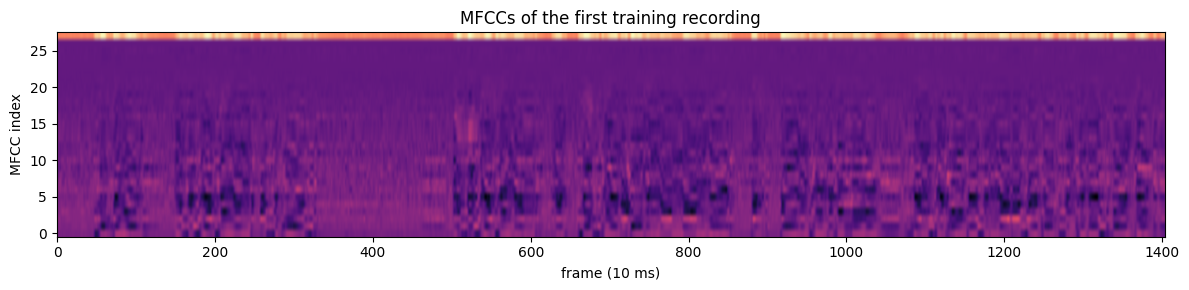

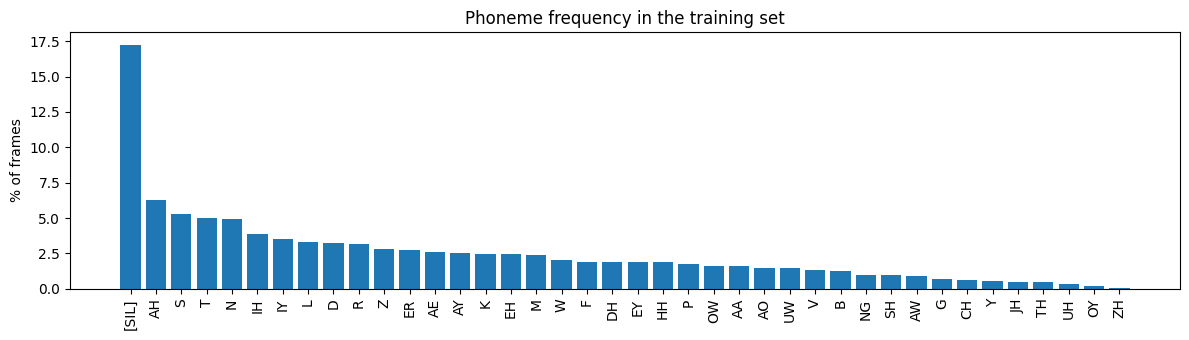

Most common class: [SIL] = 17.3% of frames


In [5]:
fig, ax = plt.subplots(figsize=(12, 3))
first = train_feats[:train_lens[0]]
ax.imshow(first.T.astype(np.float32), aspect="auto", origin="lower", cmap="magma")
ax.set_xlabel("frame (10 ms)"); ax.set_ylabel("MFCC index"); ax.set_title("MFCCs of the first training recording")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "mfcc_example.png"), dpi=150); plt.show()

counts = np.bincount(train_labels, minlength=NUM_CLASSES)
order = np.argsort(-counts)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar([PHONEMES[i] for i in order], counts[order] / counts.sum() * 100)
ax.set_ylabel("% of frames"); ax.set_title("Phoneme frequency in the training set")
plt.xticks(rotation=90); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=150); plt.show()
print(f"Most common class: {PHONEMES[order[0]]} = {counts[order[0]]/counts.sum()*100:.1f}% of frames")

## 2. Pre-processing
### 2.1 CMVN — Cepstral Mean and Variance Normalisation
Different speakers and microphones shift the MFCC values. For **each recording separately** we subtract
the mean of each coefficient and divide by its standard deviation:
$$\hat{x}_{t,d} = \frac{x_{t,d} - \mu_d}{\sigma_d + 10^{-8}}$$
so every coefficient has mean 0 and std 1 inside a recording. This also makes training easier for the network.

### 2.2 Context padding
For frame $t$ the network sees frames $t-K \dots t+K$, i.e. $2K+1$ frames $\times$ 28 = $(2K+1)\cdot 28$ inputs.
At the start and end of a recording some neighbours don't exist, so we put **K zero-frames before and
after every recording**. All padded recordings are stored one after another in one array, and we remember
the position (`centers`) of every real frame. Because of the padding, a window never mixes two recordings.

```
recording 1            recording 2
[0..0 | x x x x x | 0..0][0..0 | x x x x | 0..0] ...
  K                  K     K               K
```

The padded array is stored as **float16 directly on the GPU** (~2 GB for the full training set), so
building batches later is very fast.

In [6]:
def build_padded(feats, lens, K, use_cmvn):
    num_frames = int(lens.sum())
    padded  = np.zeros((num_frames + 2 * K * len(lens), N_MFCC), dtype=np.float16)
    centers = np.empty(num_frames, dtype=np.int64)
    src = dst = c = 0
    for L in lens:
        x = feats[src:src + L].astype(np.float32)          # compute in float32
        if use_cmvn:
            x = (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-8)
        padded[dst + K: dst + K + L] = x                   # K zeros stay before and after
        centers[c:c + L] = np.arange(dst + K, dst + K + L)  # where the real frames are
        src += L; dst += L + 2 * K; c += L
    return torch.from_numpy(padded).to(device), torch.from_numpy(centers).to(device)

# labels go to the GPU once (uint8 to save memory)
train_y = torch.from_numpy(train_labels).to(device)
dev_y   = torch.from_numpy(dev_labels).to(device)

## 3. Batching
Instead of PyTorch's `DataLoader` (multi-process loading is unreliable inside Jupyter on Windows) we build
batches ourselves, directly on the GPU:

1. `idx` = the indices of the frames in this batch (shape `B`)
2. `centers[idx]` = their positions in the padded array
3. add the offsets `-K … +K` → a `(B, 2K+1)` table of frame positions
4. index the padded array with that table → `(B, 2K+1, 28)` → flatten to `(B, (2K+1)·28)`

In [7]:
def get_batch(data, idx):
    padded, centers, y, K = data["padded"], data["centers"], data["y"], data["K"]
    offsets = torch.arange(-K, K + 1, device=device)          # (2K+1,)
    positions = centers[idx][:, None] + offsets[None, :]      # (B, 2K+1)
    x = padded[positions].reshape(len(idx), -1).float()       # (B, (2K+1)*28)
    labels = y[idx].long() if y is not None else None
    return x, labels

def make_data(feats, lens, y, K, use_cmvn):
    padded, centers = build_padded(feats, lens, K, use_cmvn)
    return {"padded": padded, "centers": centers, "y": y, "K": K}

# quick shape check
_d = make_data(dev_feats, dev_lens, dev_y, K=5, use_cmvn=True)
_x, _t = get_batch(_d, torch.arange(8, device=device))
print("batch x:", tuple(_x.shape), " batch y:", tuple(_t.shape), " expected input size:", (2*5+1)*N_MFCC)
del _d, _x, _t

batch x: (8, 308)  batch y: (8,)  expected input size: 308


## 4. The model
One configurable MLP class. Every hidden layer is a block of:

* **Linear** — weighted sum of the inputs ($Wx + b$)
* **BatchNorm1d** *(optional)* — normalises each neuron's output over the batch; makes training faster and more stable
* **Activation** — ReLU $\max(0,x)$ or GELU (a smooth version of ReLU)
* **Dropout** *(optional)* — randomly sets a fraction of neurons to 0 during training, so the network can't rely on any single neuron (reduces overfitting)

The last layer is a Linear layer with 40 outputs (the *logits*, one score per phoneme).
Softmax is not needed in the model because `nn.CrossEntropyLoss` applies it internally.

In [8]:
class PhonemeMLP(nn.Module):
    def __init__(self, input_size, hidden_sizes, num_classes=NUM_CLASSES,
                 batchnorm=False, dropout=0.0, activation="relu"):
        super().__init__()
        layers = []
        prev = input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.GELU() if activation == "gelu" else nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

PYRAMID = [2048, 2048, 1024, 1024, 512, 512]
m = PhonemeMLP((2*20+1)*N_MFCC, PYRAMID, batchnorm=True, dropout=0.2, activation="gelu")
print(m)
print(f"parameters: {count_params(m):,}")
assert count_params(m) < 20_000_000
del m

PhonemeMLP(
  (net): Sequential(
    (0): Linear(in_features=1148, out_features=2048, bias=True)
    (1): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=2048, out_features=1024, bias=True)
    (9): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): GELU(approximate='none')
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=1024, out_features=1024, bias=True)
    (13): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): GELU(approximate='none')
    (15): Dropout(p=0.2, inplace=False)
    (16): Linear(in_features=1024, out_features=5

## 5. Training and evaluation
* **Loss:** cross-entropy between the 40 logits and the true class.
* **Optimiser:** Adam, or **AdamW** (Adam + *decoupled weight decay*, a regulariser that keeps weights small).
* **Scheduler** *(optional)*: **cosine annealing** smoothly lowers the learning rate from its start value to ~0 over the epochs — big steps at the beginning, fine steps at the end.
* **Mixed precision (AMP):** the forward pass runs in float16 where it is safe → ~2× faster on the GPU. `GradScaler` scales the loss so small float16 gradients don't become zero.

**Organised run folders.** Every training run gets its own folder:
```
runs/<run_name>/
    config.json        # the settings of this run
    history.csv        # loss / accuracy / lr / time for every epoch
    best.pt            # weights of the epoch with the best dev accuracy
    epochs/epoch_01.pt # weights after every epoch
           epoch_02.pt ...
```
If a run already finished (`history.csv` has all epochs), it is **not retrained** — its results are
loaded instead. This makes it safe to restart the notebook. Set `RETRAIN = True` to force re-training.

**Progress while training.** Each run shows two progress bars:
* **total** — epochs done out of all epochs, with the **ETA** for the whole run;
* **epoch** — batches done in the current epoch, with a **countdown** of the time left in that
  epoch and the running train loss / accuracy.

In [9]:
RETRAIN = False

EPOCH_BAR = "{desc} {percentage:3.0f}%|{bar}| {n_fmt}/{total_fmt} batches [{elapsed} elapsed | {remaining} left]{postfix}"
TOTAL_BAR = "{desc} {n_fmt}/{total_fmt} epochs |{bar}| [{elapsed} elapsed | ETA {remaining}]"

def train_one_epoch(model, data, optimizer, scaler, criterion, desc="train"):
    model.train()
    n = len(data["centers"])
    perm = torch.randperm(n, device=device)                   # shuffle every epoch
    total_loss, correct, seen = 0.0, 0, 0
    bar = tqdm(range(0, n, BATCH_SIZE), desc=desc, leave=False, bar_format=EPOCH_BAR)
    for step, i in enumerate(bar):
        idx = perm[i:i + BATCH_SIZE]
        x, y = get_batch(data, idx)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(idx)
        correct += (logits.argmax(1) == y).sum().item()
        seen += len(idx)
        if step % 50 == 0:                                    # update the numbers on the bar
            bar.set_postfix_str(f"loss {total_loss/seen:.3f}  acc {correct/seen:.1%}")
    bar.close()
    return total_loss / n, correct / n

@torch.no_grad()
def predict(model, data):
    model.eval()
    n = len(data["centers"])
    preds = torch.empty(n, dtype=torch.long, device=device)
    for i in range(0, n, BATCH_SIZE * 4):
        idx = torch.arange(i, min(i + BATCH_SIZE * 4, n), device=device)
        x, _ = get_batch(data, idx)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            preds[idx] = model(x).argmax(1)
    return preds

@torch.no_grad()
def evaluate(model, data, criterion):
    model.eval()
    n = len(data["centers"])
    total_loss, correct = 0.0, 0
    for i in tqdm(range(0, n, BATCH_SIZE * 4), desc="dev eval", leave=False):
        idx = torch.arange(i, min(i + BATCH_SIZE * 4, n), device=device)
        x, y = get_batch(data, idx)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(x)
            loss = criterion(logits, y)
        total_loss += loss.item() * len(idx)
        correct += (logits.argmax(1) == y).sum().item()
    return total_loss / n, correct / n

In [10]:
def build_model(cfg):
    input_size = (2 * cfg["K"] + 1) * N_MFCC
    return PhonemeMLP(input_size, cfg["hidden"], batchnorm=cfg["batchnorm"],
                      dropout=cfg["dropout"], activation=cfg["activation"]).to(device)

def epoch_line(name, epoch, epochs, lr, tr_loss, tr_acc, dv_loss, dv_acc, secs, eta_secs):
    return (f"[{name}] epoch {epoch:2d}/{epochs}  lr {lr:.2e}  "
            f"train loss {tr_loss:.4f} acc {tr_acc*100:.2f}%  |  dev loss {dv_loss:.4f} acc {dv_acc*100:.2f}%  "
            f"|  {secs/60:.1f} min/epoch, ETA {eta_secs/60:.0f} min")

def run_experiment(name, cfg, train_data, dev_data):
    run_dir = os.path.join(RUNS_DIR, name)
    epoch_dir = os.path.join(run_dir, "epochs")
    hist_file = os.path.join(run_dir, "history.csv")
    os.makedirs(epoch_dir, exist_ok=True)

    model = build_model(cfg)
    n_params = count_params(model)

    if not RETRAIN and os.path.exists(hist_file):
        hist = pd.read_csv(hist_file)
        if len(hist) == cfg["epochs"]:
            print(f"[{name}] already trained -> loading results (saved training log below)")
            for r in hist.itertuples():
                print(epoch_line(name, r.epoch, cfg["epochs"], r.lr, r.train_loss, r.train_acc,
                                 r.dev_loss, r.dev_acc, r.seconds, r.seconds * (cfg["epochs"] - r.epoch)))
            model.load_state_dict(torch.load(os.path.join(run_dir, "best.pt"), map_location=device))
            return model, hist, n_params

    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2)

    criterion = nn.CrossEntropyLoss()
    if cfg["optimizer"] == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"]) if cfg["scheduler"] else None
    scaler = torch.amp.GradScaler("cuda")

    print(f"[{name}] params = {n_params:,}  input = {(2*cfg['K']+1)*N_MFCC}")
    history, best_acc = [], -1.0
    total_bar = tqdm(total=cfg["epochs"], desc=f"[{name}] total", bar_format=TOTAL_BAR)
    for epoch in range(1, cfg["epochs"] + 1):
        start = time.time()
        lr = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = train_one_epoch(model, train_data, optimizer, scaler, criterion,
                                          desc=f"epoch {epoch}/{cfg['epochs']}")
        dv_loss, dv_acc = evaluate(model, dev_data, criterion)
        if scheduler: scheduler.step()
        secs = time.time() - start

        torch.save(model.state_dict(), os.path.join(epoch_dir, f"epoch_{epoch:02d}.pt"))
        if dv_acc > best_acc:
            best_acc = dv_acc
            torch.save(model.state_dict(), os.path.join(run_dir, "best.pt"))

        history.append(dict(epoch=epoch, lr=lr, train_loss=tr_loss, train_acc=tr_acc,
                            dev_loss=dv_loss, dev_acc=dv_acc, seconds=secs))
        pd.DataFrame(history).to_csv(hist_file, index=False)
        total_bar.update(1)
        tqdm.write(epoch_line(name, epoch, cfg["epochs"], lr, tr_loss, tr_acc, dv_loss, dv_acc,
                              secs, secs * (cfg["epochs"] - epoch)))
    total_bar.close()

    model.load_state_dict(torch.load(os.path.join(run_dir, "best.pt"), map_location=device))
    return model, pd.DataFrame(history), n_params

## 6. Sanity check: can the model overfit one batch?
A correct model + training loop must be able to **memorise** a single small batch (accuracy → ~100%).
If it can't, something is wrong (labels misaligned, bug in batching, learning rate, ...).

In [11]:
_data = make_data(dev_feats, dev_lens, dev_y, K=5, use_cmvn=True)
_x, _y = get_batch(_data, torch.arange(0, 512, device=device) * 50)
_model = PhonemeMLP(_x.shape[1], [512, 512]).to(device)
_opt = torch.optim.Adam(_model.parameters(), lr=1e-3)
for step in range(300):
    _opt.zero_grad()
    _loss = nn.functional.cross_entropy(_model(_x), _y)
    _loss.backward(); _opt.step()
_acc = (_model(_x).argmax(1) == _y).float().mean().item()
print(f"after 300 steps on one batch: loss {_loss.item():.4f}, accuracy {_acc*100:.1f}%")
del _data, _x, _y, _model, _opt

after 300 steps on one batch: loss 0.0003, accuracy 100.0%


## 7. Ablation study
We start from a small **baseline** and add **one improvement at a time**, training each version for a few
epochs. Comparing the dev accuracy tells us how much each change helps. All later steps keep the
earlier changes.

| step | change |
|---|---|
| 1 | baseline: K=5 (11 frames), 2×512 ReLU, Adam, raw MFCCs |
| 2 | + CMVN normalisation |
| 3 | + larger context K=20 (41 frames) |
| 4 | + deeper/wider "pyramid" network with BatchNorm |
| 5 | + Dropout 0.2 |
| 6 | + GELU instead of ReLU |
| 7 | + AdamW (weight decay) + cosine learning-rate schedule |

In [12]:
ABLATION_EPOCHS = 1 if DEBUG else 3

base = dict(K=5, use_cmvn=False, hidden=[512, 512], batchnorm=False, dropout=0.0,
            activation="relu", optimizer="adam", lr=1e-3, weight_decay=0.0,
            scheduler=False, epochs=ABLATION_EPOCHS)
steps = [
    ("01_baseline",  {}),
    ("02_cmvn",      dict(use_cmvn=True)),
    ("03_context20", dict(K=20)),
    ("04_pyramid_bn",dict(hidden=PYRAMID, batchnorm=True)),
    ("05_dropout",   dict(dropout=0.2)),
    ("06_gelu",      dict(activation="gelu")),
    ("07_adamw_cos", dict(optimizer="adamw", weight_decay=0.01, scheduler=True)),
]

ablation_rows, cfg = [], dict(base)
train_data = dev_data = None
data_key = None
for name, change in steps:
    cfg = {**cfg, **change}
    key = (cfg["K"], cfg["use_cmvn"])
    if key != data_key:                      # rebuild padded data only when K or CMVN changes
        train_data = dev_data = None; torch.cuda.empty_cache()
        train_data = make_data(train_feats, train_lens, train_y, cfg["K"], cfg["use_cmvn"])
        dev_data   = make_data(dev_feats,   dev_lens,   dev_y,   cfg["K"], cfg["use_cmvn"])
        data_key = key
    set_seed(SEED)
    model, hist, n_params = run_experiment(name, cfg, train_data, dev_data)
    ablation_rows.append(dict(step=name, change=", ".join(f"{k}={v}" for k, v in change.items()) or "baseline",
                              params=n_params, best_dev_acc=hist["dev_acc"].max(),
                              min_per_epoch=hist["seconds"].mean() / 60))
    del model; torch.cuda.empty_cache()

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(os.path.join(RESULTS_DIR, "ablation.csv"), index=False)
ablation.style.format({"best_dev_acc": "{:.2%}", "params": "{:,}", "min_per_epoch": "{:.1f}"})

[01_baseline] already trained -> loading results (saved training log below)
[01_baseline] epoch  1/3  lr 1.00e-03  train loss 1.0967 acc 65.73%  |  dev loss 1.0600 acc 66.46%  |  0.3 min/epoch, ETA 1 min
[01_baseline] epoch  2/3  lr 1.00e-03  train loss 0.9642 acc 69.26%  |  dev loss 1.0152 acc 67.66%  |  0.3 min/epoch, ETA 0 min
[01_baseline] epoch  3/3  lr 1.00e-03  train loss 0.9362 acc 70.07%  |  dev loss 1.0048 acc 68.06%  |  0.3 min/epoch, ETA 0 min


[02_cmvn] already trained -> loading results (saved training log below)
[02_cmvn] epoch  1/3  lr 1.00e-03  train loss 1.0111 acc 68.09%  |  dev loss 0.9483 acc 69.64%  |  0.3 min/epoch, ETA 1 min
[02_cmvn] epoch  2/3  lr 1.00e-03  train loss 0.8829 acc 71.62%  |  dev loss 0.9056 acc 70.86%  |  0.3 min/epoch, ETA 0 min
[02_cmvn] epoch  3/3  lr 1.00e-03  train loss 0.8537 acc 72.46%  |  dev loss 0.8876 acc 71.36%  |  0.3 min/epoch, ETA 0 min


[03_context20] already trained -> loading results (saved training log below)
[03_context20] epoch  1/3  lr 1.00e-03  train loss 0.8913 acc 71.92%  |  dev loss 0.8333 acc 73.42%  |  0.3 min/epoch, ETA 1 min
[03_context20] epoch  2/3  lr 1.00e-03  train loss 0.7580 acc 75.76%  |  dev loss 0.7959 acc 74.59%  |  0.3 min/epoch, ETA 0 min
[03_context20] epoch  3/3  lr 1.00e-03  train loss 0.7267 acc 76.70%  |  dev loss 0.7734 acc 75.24%  |  0.3 min/epoch, ETA 0 min
[04_pyramid_bn] already trained -> loading results (saved training log below)
[04_pyramid_bn] epoch  1/3  lr 1.00e-03  train loss 0.6432 acc 78.79%  |  dev loss 0.5979 acc 80.20%  |  3.1 min/epoch, ETA 6 min
[04_pyramid_bn] epoch  2/3  lr 1.00e-03  train loss 0.4445 acc 84.76%  |  dev loss 0.5782 acc 81.15%  |  3.1 min/epoch, ETA 3 min
[04_pyramid_bn] epoch  3/3  lr 1.00e-03  train loss 0.3700 acc 87.05%  |  dev loss 0.5956 acc 81.28%  |  3.1 min/epoch, ETA 0 min
[05_dropout] already trained -> loading results (saved training log 

[07_adamw_cos] already trained -> loading results (saved training log below)
[07_adamw_cos] epoch  1/3  lr 1.00e-03  train loss 0.7597 acc 75.46%  |  dev loss 0.5932 acc 80.18%  |  3.4 min/epoch, ETA 7 min
[07_adamw_cos] epoch  2/3  lr 7.50e-04  train loss 0.5659 acc 81.17%  |  dev loss 0.5381 acc 81.91%  |  3.4 min/epoch, ETA 3 min
[07_adamw_cos] epoch  3/3  lr 2.50e-04  train loss 0.4985 acc 83.18%  |  dev loss 0.5079 acc 82.90%  |  3.4 min/epoch, ETA 0 min


,step,change,params,best_dev_acc,min_per_epoch
0,01_baseline,baseline,"441,384",68.06%,0.3
1,02_cmvn,use_cmvn=True,"441,384",71.36%,0.3
2,03_context20,K=20,"871,464",75.24%,0.3
3,04_pyramid_bn,"hidden=[2048, 2048, 1024, 1024, 512, 512], batchnorm=True","10,519,592",81.28%,3.1
4,05_dropout,dropout=0.2,"10,519,592",81.74%,3.3
5,06_gelu,activation=gelu,"10,519,592",82.55%,3.3
6,07_adamw_cos,"optimizer=adamw, weight_decay=0.01, scheduler=True","10,519,592",82.90%,3.4


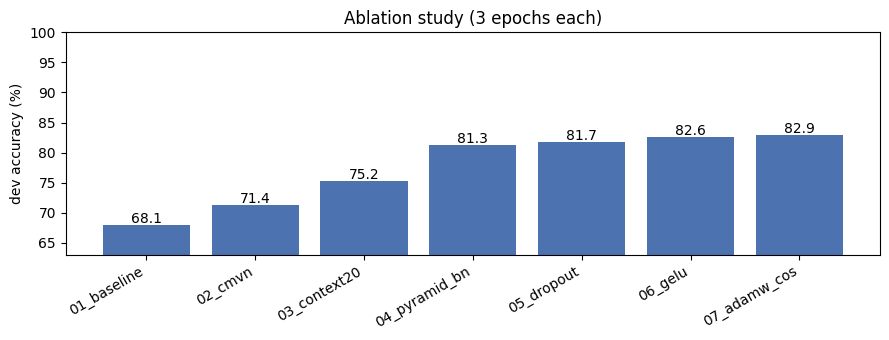

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(ablation["step"], ablation["best_dev_acc"] * 100, color="#4C72B0")
for i, v in enumerate(ablation["best_dev_acc"] * 100):
    ax.text(i, v + 0.3, f"{v:.1f}", ha="center")
ax.set_ylabel("dev accuracy (%)"); ax.set_title(f"Ablation study ({ABLATION_EPOCHS} epochs each)")
ax.set_ylim(ablation["best_dev_acc"].min() * 100 - 5, 100)
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ablation.png"), dpi=150); plt.show()

## 8. Final training
The best configuration (step 7) is trained for longer. The cosine schedule is stretched over all epochs.
After each epoch the notebook prints the time per epoch and an **ETA**. The weights of every epoch are
saved in `runs/final/epochs/`, and the best one in `runs/final/best.pt`.

In [14]:
FINAL_EPOCHS = 2 if DEBUG else 20
final_cfg = {**cfg, "epochs": FINAL_EPOCHS}
print(json.dumps(final_cfg, indent=2))

set_seed(SEED)
final_model, final_hist, final_params = run_experiment("final", final_cfg, train_data, dev_data)
print(f"best dev accuracy: {final_hist['dev_acc'].max()*100:.2f}%  (epoch {final_hist['dev_acc'].idxmax()+1})")

{
  "K": 20,
  "use_cmvn": true,
  "hidden": [
    2048,
    2048,
    1024,
    1024,
    512,
    512
  ],
  "batchnorm": true,
  "dropout": 0.2,
  "activation": "gelu",
  "optimizer": "adamw",
  "lr": 0.001,
  "weight_decay": 0.01,
  "scheduler": true,
  "epochs": 20
}
[final] already trained -> loading results (saved training log below)
[final] epoch  1/20  lr 1.00e-03  train loss 0.7597 acc 75.46%  |  dev loss 0.5932 acc 80.18%  |  3.4 min/epoch, ETA 64 min
[final] epoch  2/20  lr 9.94e-04  train loss 0.5760 acc 80.86%  |  dev loss 0.5413 acc 81.79%  |  3.4 min/epoch, ETA 61 min
[final] epoch  3/20  lr 9.76e-04  train loss 0.5291 acc 82.25%  |  dev loss 0.5192 acc 82.51%  |  3.4 min/epoch, ETA 58 min
[final] epoch  4/20  lr 9.46e-04  train loss 0.5026 acc 83.04%  |  dev loss 0.5086 acc 82.89%  |  3.4 min/epoch, ETA 54 min
[final] epoch  5/20  lr 9.05e-04  train loss 0.4843 acc 83.58%  |  dev loss 0.4998 acc 83.17%  |  3.4 min/epoch, ETA 51 min
[final] epoch  6/20  lr 8.54e-04  tra

## 9. Analysis
1. **Learning curves** — loss and accuracy for train and dev per epoch. If train keeps improving while dev
   gets worse, the model overfits.
2. **Per-phoneme accuracy** — which sounds are easy and which are hard.
3. **Confusion matrix** — which phonemes are mistaken for which (row = true, column = predicted).

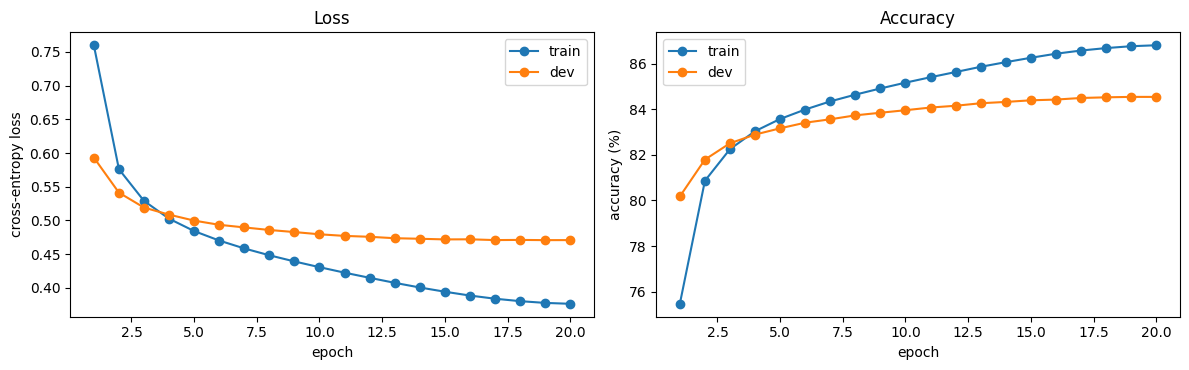

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(final_hist["epoch"], final_hist["train_loss"], "o-", label="train")
axes[0].plot(final_hist["epoch"], final_hist["dev_loss"], "o-", label="dev")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].legend(); axes[0].set_title("Loss")
axes[1].plot(final_hist["epoch"], final_hist["train_acc"] * 100, "o-", label="train")
axes[1].plot(final_hist["epoch"], final_hist["dev_acc"] * 100, "o-", label="dev")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (%)"); axes[1].legend(); axes[1].set_title("Accuracy")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "learning_curves.png"), dpi=150); plt.show()

dev accuracy: 84.55%


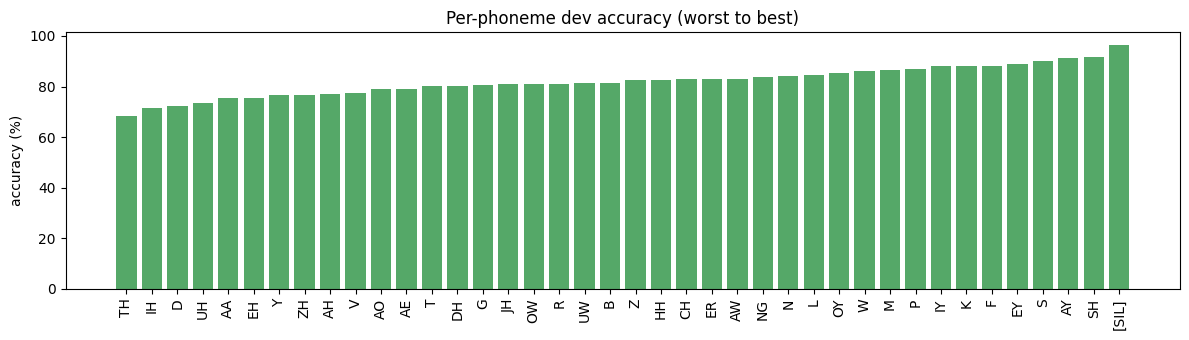

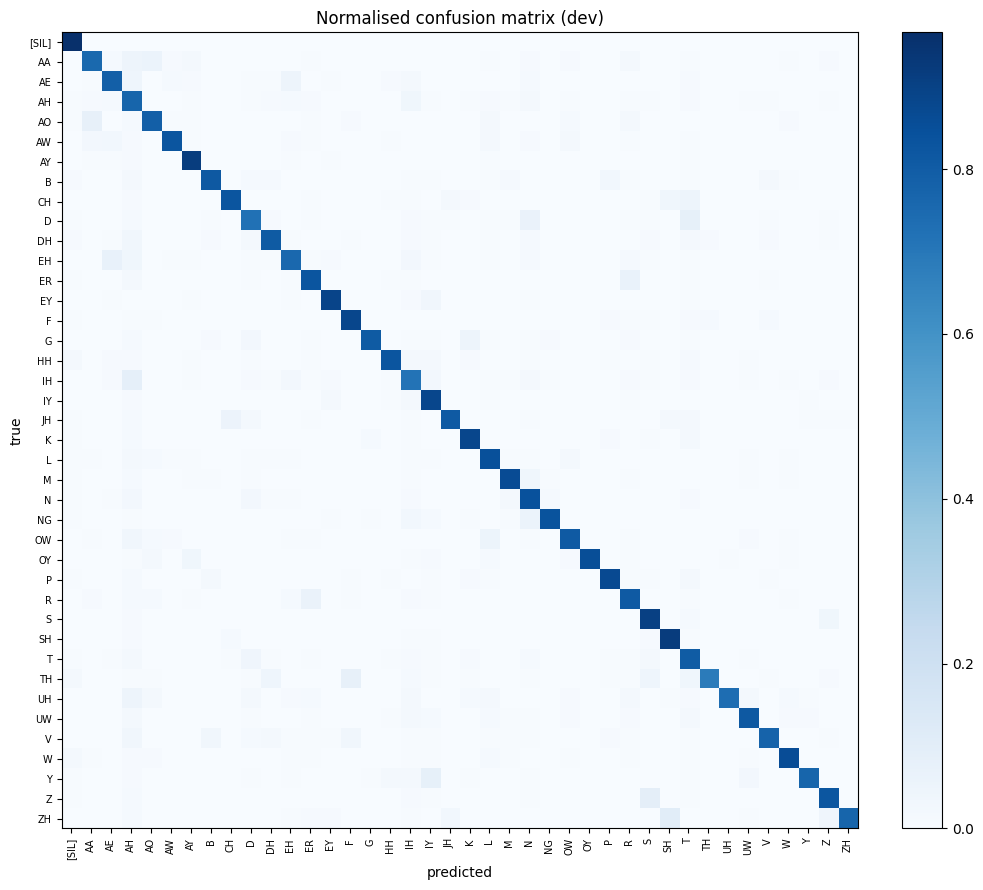

,true,predicted,% of true class
0,ZH,SH,10.471807
1,Z,S,9.221513
2,IH,AH,8.650367
3,Y,IY,8.284207
4,D,T,7.925051
5,TH,F,7.591651
6,AO,AA,7.549421
7,EH,AE,6.877229
8,ER,R,6.568599
9,R,ER,6.341129


In [16]:
from sklearn.metrics import confusion_matrix

dev_pred = predict(final_model, dev_data).cpu().numpy()
dev_true = dev_labels.astype(np.int64)
cm = confusion_matrix(dev_true, dev_pred, labels=range(NUM_CLASSES))
per_class_acc = cm.diagonal() / cm.sum(axis=1)
print(f"dev accuracy: {(dev_pred == dev_true).mean()*100:.2f}%")

order = np.argsort(per_class_acc)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar([PHONEMES[i] for i in order], per_class_acc[order] * 100, color="#55A868")
ax.set_ylabel("accuracy (%)"); ax.set_title("Per-phoneme dev accuracy (worst to best)")
plt.xticks(rotation=90); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "per_class_acc.png"), dpi=150); plt.show()

cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm_norm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(PHONEMES, rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(PHONEMES, fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Normalised confusion matrix (dev)")
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrix.png"), dpi=150); plt.show()

# the most frequent mistakes
off = cm_norm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:10], off.shape))[0]
confusions = pd.DataFrame([(PHONEMES[t], PHONEMES[p], off[t, p] * 100) for t, p in top],
                          columns=["true", "predicted", "% of true class"])
confusions.to_csv(os.path.join(RESULTS_DIR, "top_confusions.csv"), index=False)
pd.DataFrame({"phoneme": PHONEMES, "dev_acc": per_class_acc, "frames": cm.sum(axis=1)}) \
  .to_csv(os.path.join(RESULTS_DIR, "per_class_acc.csv"), index=False)
confusions

## 10. Test predictions and submission
The test recordings are processed exactly like the dev set (same K, same CMVN), in **sorted file order**.
Kaggle expects one row per frame: `id` = running frame number, `label` = phoneme string.

In [17]:
test_data = make_data(test_feats, test_lens, None, final_cfg["K"], final_cfg["use_cmvn"])
test_pred = predict(final_model, test_data).cpu().numpy()

submission = pd.DataFrame({"id": np.arange(len(test_pred)),
                           "label": [PHONEMES[i] for i in test_pred]})
assert len(submission) == int(test_lens.sum())
submission.to_csv("submission.csv", index=False)
print(submission.shape); submission.head()

(1934138, 2)


,id,label
0,0,[SIL]
1,1,[SIL]
2,2,[SIL]
3,3,[SIL]
4,4,[SIL]


In [18]:
summary = dict(final_params=final_params, best_dev_acc=float(final_hist["dev_acc"].max()),
               best_epoch=int(final_hist["dev_acc"].idxmax() + 1),
               total_train_minutes=float(final_hist["seconds"].sum() / 60), config=final_cfg)
with open(os.path.join(RESULTS_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
summary

{'final_params': 10519592,
 'best_dev_acc': 0.8454681143696414,
 'best_epoch': 19,
 'total_train_minutes': 67.577168738842,
 'config': {'K': 20,
  'use_cmvn': True,
  'hidden': [2048, 2048, 1024, 1024, 512, 512],
  'batchnorm': True,
  'dropout': 0.2,
  'activation': 'gelu',
  'optimizer': 'adamw',
  'lr': 0.001,
  'weight_decay': 0.01,
  'scheduler': True,
  'epochs': 20}}